## Import Library


In [1]:
# 202431077_Siti Shafira Shafarina Amirullah

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

## Membaca Dataset

In [2]:
# 202431077_Siti Shafira Shafarina Amirullah

df = pd.read_csv('data_gedung_bersih.csv')

print("Data Awal:")
display(df.head())

Data Awal:


,kota,negara,gedung,tinggi_m,lantai,tahun
0,Dubai,United Arab Emirates,Burj Khalifa,828.0,163,2010
1,Kuala Lumpur,Malaysia,Merdeka 118,678.9,118,2024
2,Shanghai,China,Shanghai Tower,632.0,128,2015
3,Mecca,Saudi Arabia,Makkah Royal Clock Tower,601.0,120,2012
4,Shenzhen,China,Ping An International Finance Centre,599.1,115,2017


## Melihat Informasi Dataset

In [3]:
# 202431077_Siti Shafira Shafarina Amirullah

print("Informasi Dataset:")
df.info()

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 923 entries, 0 to 922
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   kota      923 non-null    object 
 1   negara    923 non-null    object 
 2   gedung    923 non-null    object 
 3   tinggi_m  923 non-null    float64
 4   lantai    923 non-null    int64  
 5   tahun     923 non-null    int64  
dtypes: float64(1), int64(2), object(3)
memory usage: 43.4+ KB


## Melihat Deskripsi Statistik

In [4]:
# 202431077_Siti Shafira Shafarina Amirullah

print("Deskripsi Statistik Dataset:")
display(df.describe())

Deskripsi Statistik Dataset:


,tinggi_m,lantai,tahun
count,923.000000,923.000000,923.000000
mean,173.146804,42.341278,2010.052004
std,86.252680,17.429545,15.953481
min,100.000000,14.000000,1927.000000
25%,118.000000,31.000000,2005.000000
50%,143.700000,37.000000,2016.000000
75%,195.600000,49.000000,2021.000000
max,828.000000,163.000000,2028.000000


## Mengecek Data Kosong 

In [5]:
# 202431077_Siti Shafira Shafarina Amirullah

print("Jumlah Data Kosong:")
print(df.isna().sum())

Jumlah Data Kosong:
kota        0
negara      0
gedung      0
tinggi_m    0
lantai      0
tahun       0
dtype: int64


## Membuat Kategori Target dan Melihat Nilai Unik

In [6]:
# 202431077_Siti Shafira Shafarina Amirullah

df['kategori_tinggi'] = pd.qcut(
    df['tinggi_m'],
    q=3,
    labels=['Rendah', 'Sedang', 'Tinggi']
)

print("Nilai Unik Target:")
print(df['kategori_tinggi'].unique())

print("\nJumlah Data Setiap Kategori:")
print(df['kategori_tinggi'].value_counts())

Nilai Unik Target:
['Tinggi', 'Sedang', 'Rendah']
Categories (3, object): ['Rendah' < 'Sedang' < 'Tinggi']

Jumlah Data Setiap Kategori:
kategori_tinggi
Rendah    312
Tinggi    308
Sedang    303
Name: count, dtype: int64


## Memisahkan Fitur (X) dan Target (y)

In [7]:
# 202431077_Siti Shafira Shafarina Amirullah

X = df[['lantai', 'tahun']]
y = df['kategori_tinggi']

print("Fitur (X):")
display(X.head())

print("Target (y):")
display(y.head())

Fitur (X):


,lantai,tahun
0,163,2010
1,118,2024
2,128,2015
3,120,2012
4,115,2017


Target (y):


0    Tinggi
1    Tinggi
2    Tinggi
3    Tinggi
4    Tinggi
Name: kategori_tinggi, dtype: category
Categories (3, object): ['Rendah' < 'Sedang' < 'Tinggi']

## Mengubah Data Menjadi Array Angka

In [8]:
# 202431077_Siti Shafira Shafarina Amirullah

label_encoder = LabelEncoder()

X = np.array(X, dtype=np.float64)
y = label_encoder.fit_transform(y).astype(np.int64)

print("Fitur X setelah dikonversi:")
print(X[:5])

print("\nTarget y setelah dikonversi:")
print(y[:5])

print("\nMapping Kategori:")
for i, kelas in enumerate(label_encoder.classes_):
    print(i, "=", kelas)

Fitur X setelah dikonversi:
[[ 163. 2010.]
 [ 118. 2024.]
 [ 128. 2015.]
 [ 120. 2012.]
 [ 115. 2017.]]

Target y setelah dikonversi:
[2 2 2 2 2]

Mapping Kategori:
0 = Rendah
1 = Sedang
2 = Tinggi


## Membagi Data Training dan Testing

In [9]:
# 202431077_Siti Shafira Shafarina Amirullah

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

print("Jumlah Data Latih:", len(X_train))
print("Jumlah Data Uji:", len(X_test))

Jumlah Data Latih: 646
Jumlah Data Uji: 277


## Membuat dan Melatih Model Decision Tree

In [10]:
# 202431077_Siti Shafira Shafarina Amirullah

model = DecisionTreeClassifier(random_state=0)

model.fit(X_train, y_train)

print("Model Decision Tree berhasil dilatih!")

Model Decision Tree berhasil dilatih!


## Visualisasi Pohon Keputusan 

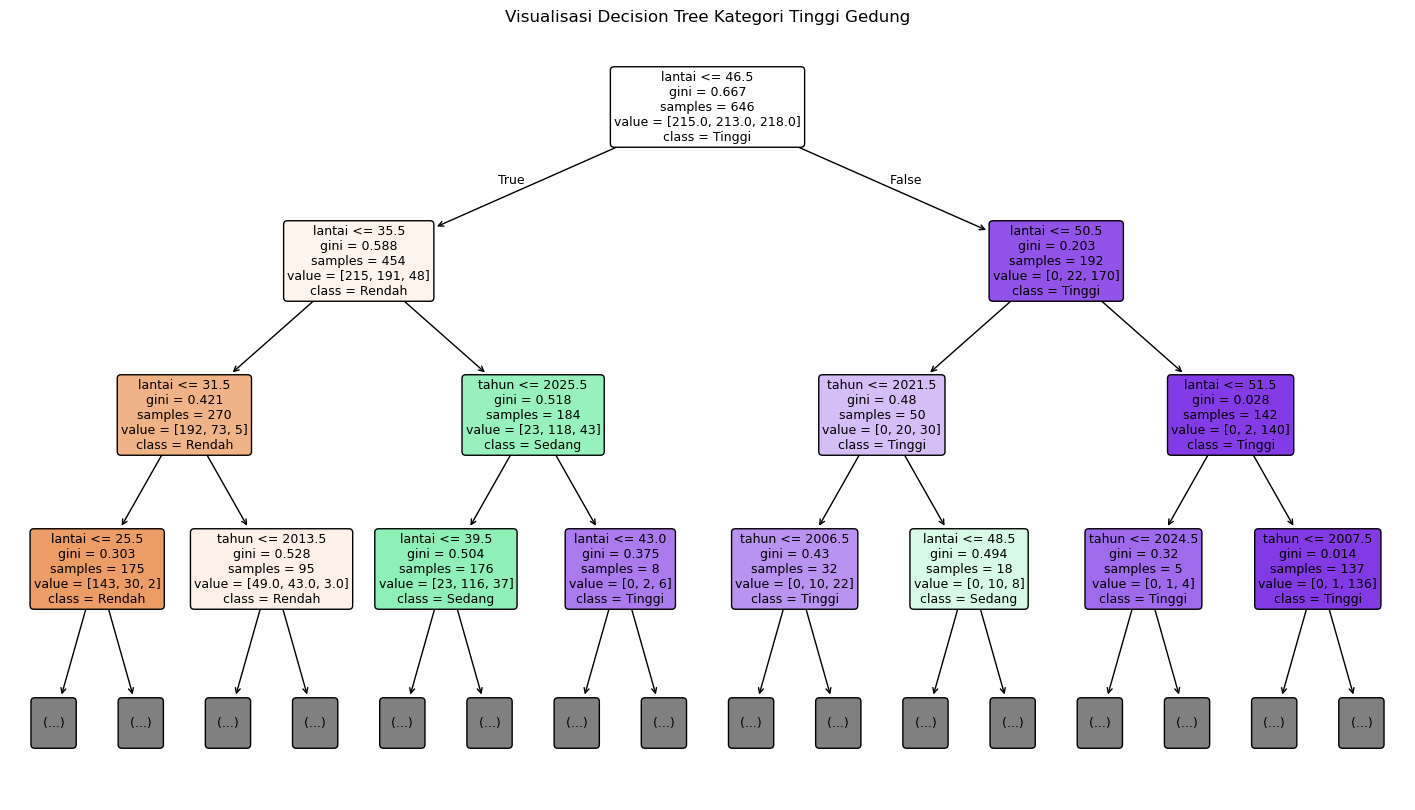

In [11]:
# 202431077_Siti Shafira Shafarina Amirullah

plt.figure(figsize=(18, 10))

plot_tree(
    model,
    feature_names=['lantai', 'tahun'],
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Visualisasi Decision Tree Kategori Tinggi Gedung")
plt.show()

## Menguji dengan 1 Data Baru

In [12]:
# 202431077_Siti Shafira Shafarina Amirullah

data_baru = np.array([[100, 2020]], dtype=np.float64)

hasil_prediksi = model.predict(data_baru)

kategori_prediksi = label_encoder.inverse_transform(hasil_prediksi)

print("Data Baru:")
print("Jumlah Lantai:", data_baru[0][0])
print("Tahun Pembangunan:", data_baru[0][1])

print("\nHasil Prediksi Kategori Tinggi Gedung:")
print(kategori_prediksi[0])

Data Baru:
Jumlah Lantai: 100.0
Tahun Pembangunan: 2020.0

Hasil Prediksi Kategori Tinggi Gedung:
Tinggi


## Menghitung Akurasi

In [13]:
# 202431077_Siti Shafira Shafarina Amirullah

y_pred = model.predict(X_test)

akurasi = accuracy_score(y_test, y_pred)

print("Akurasi Model Decision Tree:", akurasi)
print("Persentase Akurasi:", akurasi * 100, "%")

Akurasi Model Decision Tree: 0.6606498194945848
Persentase Akurasi: 66.06498194945848 %


## Classification Report

In [14]:
# 202431077_Siti Shafira Shafarina Amirullah

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

Classification Report:
              precision    recall  f1-score   support

      Rendah       0.65      0.74      0.69        97
      Sedang       0.51      0.50      0.50        90
      Tinggi       0.86      0.73      0.79        90

    accuracy                           0.66       277
   macro avg       0.67      0.66      0.66       277
weighted avg       0.67      0.66      0.66       277

